<a href="https://colab.research.google.com/github/4xuanzhou/GIS/blob/main/ps2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Community Health Assessment of Central New Jersey Communities Surrounding Compressor Stations

Natural gas compressor stations are part of the infrastructure used to transport natural gas through pipelines. Their operations may contribute to ambient air pollution, including fine particulate matter (PM2.5), which has been associated with adverse respiratory health outcomes. This study examines the spatial distribution of compressor stations, PM2.5 concentrations, and adult asthma prevalence in central New Jersey to explore patterns in environmental exposure and respiratory health.

#### Unit of Analysis

The primary unit of analysis is the census tract. The study examines census-tract-level annual average PM2.5 concentrations and crude prevalence of current asthma among adults. County-level summaries are also used to describe changes in asthma prevalence between the two comparison periods.

#### Research Questions

1.   How are natural gas compressor stations distributed across central New Jersey, and which stations underwent major expansion during the study period?
2.   How did annual average PM2.5 concentrations vary spatially between 2015 and 2021?
3.   How did the prevalence of current asthma among adults vary spatially across New Jersey between 2018 and 2023?
4.   What is the association between annual average PM2.5 concentrations and crude adult asthma prevalence at the census-tract level?



#### Hypotheses

1. Census tracts with higher annual average PM2.5 concentrations will tend to have higher crude prevalence of current asthma among adults.
2. The association between PM2.5 concentrations and asthma prevalence may differ between the two comparison periods.
3. The expansion of a compressor station may have an impact on the local communities' changes in PM2.5 and asthma prevalence over time.


In [88]:
%%capture
#!pip install geopandas #==1.0.1
!pip install mapclassify #sometimes have to install library which you get from https://pypi.org/

In [89]:
import os, zipfile #basics
import pandas as pd #data management
import matplotlib.pyplot as plt #vis
import matplotlib as mpl
import matplotlib.patheffects as path_effects

import geopandas as gpd #gis/maps: a sister of pandas; does the job;
#tho not as fancy-interactive as folium or leafmap https://geopandas.org/

import mapclassify #need for thematic map classification

import seaborn as sns


#will display all output not just last command
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

from google.colab import files #to download from colab onto hd

#from google.colab import data_table
#data_table.enable_dataframe_formatter() #this enables spreadsheet view upon calling dataframe (without() )
from google.colab.data_table import DataTable
DataTable.max_columns = 250

In [90]:
#!python --version
gpd.__version__

'1.2.0'

In [91]:
import zipfile # Import zipfile module

! wget -q -O nj0.zip https://github.com/4xuanzhou/GIS/raw/refs/heads/main/tl_2025_34_tract.zip
zip_ref = zipfile.ZipFile('nj0.zip', 'r'); zip_ref.extractall(); zip_ref.close() #just unzipping
!ls #see what we got

nj0=gpd.read_file('tl_2025_34_tract.shp') #load the shapefile with gpd as nj0

# nj0.dtypes
nj0.head()



# 2015
! wget -q -O nj2015.zip https://github.com/4xuanzhou/GIS/raw/refs/heads/main/tl_2015_34_tract.zip

zip_ref = zipfile.ZipFile('nj2015.zip', 'r'); zip_ref.extractall(); zip_ref.close() #just unzipping
!ls #see what we got

nj2015=gpd.read_file('tl_2015_34_tract.shp') #load the shapefile with gpd as nj2015


nj2015.head()

cdc_places_tract_data_2020.csv
cdc_places_tract_data.csv
cs.zip
Daily_Census_Tract-Level_PM2.5_Concentrations._2011-2015_20261014.csv
Daily_Census_Tract-Level_PM2.5_Concentrations._2021-_2022_20261013.csv
Natural_Gas_Compressor_Stations.cpg
Natural_Gas_Compressor_Stations.dbf
Natural_Gas_Compressor_Stations.prj
Natural_Gas_Compressor_Stations.shp
Natural_Gas_Compressor_Stations.shx
Natural_Gas_Compressor_Stations.xml
nj0.zip
nj2015.zip
sample_data
tl_2015_34_tract.cpg
tl_2015_34_tract.dbf
tl_2015_34_tract.prj
tl_2015_34_tract.shp
tl_2015_34_tract.shp.ea.iso.xml
tl_2015_34_tract.shp.iso.xml
tl_2015_34_tract.shp.xml
tl_2015_34_tract.shx
tl_2025_34_tract.cpg
tl_2025_34_tract.dbf
tl_2025_34_tract.prj
tl_2025_34_tract.shp
tl_2025_34_tract.shp.ea.iso.xml
tl_2025_34_tract.shp.iso.xml
tl_2025_34_tract.shx


,STATEFP,COUNTYFP,TRACTCE,GEOID,GEOIDFQ,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,34,021,002702,34021002702,1400000US34021002702,27.02,Census Tract 27.02,G5020,S,5399790,15413,+40.2169255,-074.7000479,"POLYGON ((-74.72001 40.22311, -74.71984 40.223..."
1,34,021,002800,34021002800,1400000US34021002800,28,Census Tract 28,G5020,S,2317338,1972,+40.2282073,-074.7235843,"POLYGON ((-74.73948 40.23151, -74.73939 40.231..."
2,34,021,002902,34021002902,1400000US34021002902,29.02,Census Tract 29.02,G5020,S,4990120,111611,+40.2363258,-074.7184493,"POLYGON ((-74.73856 40.23464, -74.73852 40.234..."
3,34,021,002904,34021002904,1400000US34021002904,29.04,Census Tract 29.04,G5020,S,7597739,49442,+40.2568316,-074.6776468,"POLYGON ((-74.69678 40.25125, -74.69669 40.251..."
4,34,033,020200,34033020200,1400000US34033020200,202,Census Tract 202,G5020,S,951186,0,+39.7320131,-075.4672011,"POLYGON ((-75.47565 39.7337, -75.47551 39.7337..."


cdc_places_tract_data_2020.csv
cdc_places_tract_data.csv
cs.zip
Daily_Census_Tract-Level_PM2.5_Concentrations._2011-2015_20261014.csv
Daily_Census_Tract-Level_PM2.5_Concentrations._2021-_2022_20261013.csv
Natural_Gas_Compressor_Stations.cpg
Natural_Gas_Compressor_Stations.dbf
Natural_Gas_Compressor_Stations.prj
Natural_Gas_Compressor_Stations.shp
Natural_Gas_Compressor_Stations.shx
Natural_Gas_Compressor_Stations.xml
nj0.zip
nj2015.zip
sample_data
tl_2015_34_tract.cpg
tl_2015_34_tract.dbf
tl_2015_34_tract.prj
tl_2015_34_tract.shp
tl_2015_34_tract.shp.ea.iso.xml
tl_2015_34_tract.shp.iso.xml
tl_2015_34_tract.shp.xml
tl_2015_34_tract.shx
tl_2025_34_tract.cpg
tl_2025_34_tract.dbf
tl_2025_34_tract.prj
tl_2025_34_tract.shp
tl_2025_34_tract.shp.ea.iso.xml
tl_2025_34_tract.shp.iso.xml
tl_2025_34_tract.shx


,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,34,031,256804,34031256804,2568.04,Census Tract 2568.04,G5020,S,29980406,810253,+41.0787934,-074.3779531,"POLYGON ((-74.41591 41.08861, -74.41484 41.089..."
1,34,031,246300,34031246300,2463,Census Tract 2463,G5020,S,9998668,528595,+40.9104210,-074.2642143,"POLYGON ((-74.28918 40.92872, -74.28902 40.928..."
2,34,031,256803,34031256803,2568.03,Census Tract 2568.03,G5020,S,14210045,762325,+41.1220242,-074.3806122,"POLYGON ((-74.41296 41.11469, -74.41051 41.117..."
3,34,031,246003,34031246003,2460.03,Census Tract 2460.03,G5020,S,6599340,1724481,+40.9770103,-074.2610348,"POLYGON ((-74.28209 40.96986, -74.28209 40.969..."
4,34,031,256805,34031256805,2568.05,Census Tract 2568.05,G5020,S,87448935,6245422,+41.0968573,-074.4256687,"POLYGON ((-74.50286 41.08593, -74.50279 41.086..."


In [92]:
# Make the map of NJ
# Not interested in South or North Jersey,
# so I will filter in the next steps and then plot Central Jersey
# nj0.plot()

In [93]:


# Define the lists of counties for Central Jersey
central_counties = ['Hunterdon', 'Mercer', 'Middlesex', 'Monmouth', 'Somerset', 'Union']

# Manually created mapping of county names to FIPS codes for New Jersey
# These FIPS codes are standard 2-digit codes for NJ counties (as strings)
nj_county_fips_mapping = {
    'Atlantic': '001', 'Bergen': '003', 'Burlington': '005', 'Camden': '007',
    'Cape May': '009', 'Cumberland': '011', 'Essex': '013', 'Gloucester': '015',
    'Hudson': '017', 'Hunterdon': '019', 'Mercer': '021', 'Middlesex': '023',
    'Monmouth': '025', 'Morris': '027', 'Ocean': '029', 'Passaic': '031',
    'Salem': '033', 'Somerset': '035', 'Sussex': '037', 'Union': '039',
    'Warren': '041'
}

# Get the FIPS codes for Central counties
central_counties_fips = [
    nj_county_fips_mapping[county_name]
    for county_name in central_counties
    if county_name in nj_county_fips_mapping
]
# central_counties_fips

# Filter the GeoDataFrame using COUNTYFP column and FIPS codes
central_jersey_map = nj0[nj0['COUNTYFP'].isin(central_counties_fips)]
#central_jersey_map.plot()

# 2015
central_jersey_map2015 = nj2015[nj2015['COUNTYFP'].isin(central_counties_fips)]
#central_jersey_map2015.plot()


In [94]:
central_jersey_map.head()
central_jersey_map.dtypes
central_jersey_map.columns
central_jersey_map.shape[0]

,STATEFP,COUNTYFP,TRACTCE,GEOID,GEOIDFQ,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,34,021,002702,34021002702,1400000US34021002702,27.02,Census Tract 27.02,G5020,S,5399790,15413,+40.2169255,-074.7000479,"POLYGON ((-74.72001 40.22311, -74.71984 40.223..."
1,34,021,002800,34021002800,1400000US34021002800,28,Census Tract 28,G5020,S,2317338,1972,+40.2282073,-074.7235843,"POLYGON ((-74.73948 40.23151, -74.73939 40.231..."
2,34,021,002902,34021002902,1400000US34021002902,29.02,Census Tract 29.02,G5020,S,4990120,111611,+40.2363258,-074.7184493,"POLYGON ((-74.73856 40.23464, -74.73852 40.234..."
3,34,021,002904,34021002904,1400000US34021002904,29.04,Census Tract 29.04,G5020,S,7597739,49442,+40.2568316,-074.6776468,"POLYGON ((-74.69678 40.25125, -74.69669 40.251..."
18,34,023,000503,34023000503,1400000US34023000503,5.03,Census Tract 5.03,G5020,S,1478476,42498,+40.5730745,-074.4489446,"POLYGON ((-74.45402 40.5778, -74.4536 40.5779,..."


,0
STATEFP,object
COUNTYFP,object
TRACTCE,object
GEOID,object
GEOIDFQ,object
NAME,object
NAMELSAD,object
MTFCC,object
FUNCSTAT,object
ALAND,int64


Index(['STATEFP', 'COUNTYFP', 'TRACTCE', 'GEOID', 'GEOIDFQ', 'NAME',
       'NAMELSAD', 'MTFCC', 'FUNCSTAT', 'ALAND', 'AWATER', 'INTPTLAT',
       'INTPTLON', 'geometry'],
      dtype='object')

655

In [102]:
# get shapefile of natural gas compressor stations
!wget -q -O cs.zip  https://github.com/4xuanzhou/GIS/raw/refs/heads/main/Natural_Gas_Compressor_Stations.zip
zip_ref = zipfile.ZipFile('cs.zip', 'r');zip_ref.extractall(); zip_ref.close()
# cs0 is national
cs0 = gpd.read_file('Natural_Gas_Compressor_Stations.shp')
#cs0.dtypes
#cs0.head(3)
cs0.columns

Index(['OBJECTID_1', 'OBJECTID', 'GCOMPID', 'NAME', 'ADDRESS', 'CITY', 'STATE',
       'ZIP', 'ZIP4', 'TYPE', 'STATUS', 'COUNTY', 'COUNTYFIPS', 'COUNTRY',
       'LATITUDE', 'LONGITUDE', 'NAICS_CODE', 'NAICS_DESC', 'SOURCE',
       'SOURCEDATE', 'VAL_METHOD', 'VAL_DATE', 'WEBSITE', 'PIPECO', 'COMPID',
       'OPERATOR', 'POSREL', 'NUM_UNITS', 'CERT_HP', 'PLANT_COST', 'EXP_FUEL',
       'EXP_OTHER', 'GAS_COMPRE', 'OP_COMP_HR', 'OP_NUM_COM', 'OP_DATE_PE',
       'EXP_POWER', 'ELEC_COMPR', 'geometry'],
      dtype='object')

In [103]:
# Limit to STATE "NJ"
cs = cs0[cs0['STATE'] == 'NJ']
# cs only has NJ compressor stations

# Check duplicates in cs0,
dupes = cs[cs.duplicated(subset='NAME', keep=False)]
print(dupes[['NAME', 'LATITUDE', 'LONGITUDE', 'OPERATOR', 'GCOMPID', 'OBJECTID', 'STATE', 'CITY', 'ADDRESS']])
# Checked other info to confirm these were true duplicates, not distinct stations
# I decided to keep them, because their operators are different, so maybe they are different facilities

        NAME   LATITUDE  LONGITUDE                         OPERATOR  \
240  HANOVER  40.791597 -74.429208   TEXAS EASTERN TRANSMISSION, LP   
952  HANOVER  40.799881 -74.427718  ALGONQUIN GAS TRANSMISSION, LLC   

       GCOMPID  OBJECTID STATE        CITY               ADDRESS  
240  GCOMP1214       241    NJ  MORRISTOWN  OFF OF COLUMBIA TPKE  
952   GCOMP625       953    NJ  MORRISTOWN         45 AIRPORT RD  


#### Natrual gas compressor stations

The locations of six natural gas compressor stations in central New Jersey were obtained from the 543rd Geospatial Planning Cell (2021). The stations were constructed by two pipeline companies: Transcontinental Gas Pipe Line Company (Transco), which operates Stations 205, 207, and 505, and Texas Eastern Transmission (Tetco), which operates the Linden, Lambertville, and Freehold stations. According to Oil & Gas Watch (2024), Compressor Station 207 underwent a major expansion beginning in December 2016, making it particularly relevant to the study period. Although Compressor Station 206 has been proposed in Franklin Township, it has not been constructed and is therefore excluded from the map.




More construction and expansion information:

Transcontinental Gas Pipe Line Company (Transco) constructed Compressor Station 205, 207, and 505.
*   Compressor Station 205 (Mercer County, NJ): Originally built in the early 1950s. Expansion and modernization phases included an upgrade in 2001 (adding a 15,000 hp electric unit).
*   Compressor Station 207 (Midd Middlesex County, NJ): Constructed in the early 1950s. It saw significant expansion project construction starting in December 2016 and further facility modifications.
*   Compressor Station 505 (Somerset County, NJ): Originally built in the mid-20th century. A massive modernization and replacement construction project was initiated in 2023–2024, which replaced eight aging internal combustion engines with two new natural gas-fired turbines.

Texas Eastern Transmission (Tetco) constructed Compressor Station Linden, Lambertville, and Freehold.

*   Linden Compressor Station (Union County, NJ): Originally built in the 1950s. It underwent significant replacement and loop construction around 2011–2012.
*   Lambertville Compressor Station (Hunterdon County, NJ): Constructed in the 1950s. It underwent a major capacity uprate in 2001 and a subsequent overhaul (the Lambertville East Expansion) which completed construction and entered service in November 2019. A solar farm to power the station began construction in May 2020.
*   Freehold Compressor Station (Somerset County, NJ): The 5,000-horsepower electric facility was built shortly after the company filed its intent to construct in December 2001.

It's notable that 'Franklin (Freehold)' on the plot refers to Freehold Compressor Station, different from the newly proposed Compressor Station 206 (CS 206). CS 206 hasn't been constructed and is not reflected on the plot.

In [104]:
# The CRS-checking (.crs) and spatial join (sjoin) steps below were done with help from Claude

# Check/match CRS first
if cs.crs != central_jersey_map.crs:
    cs = cs.to_crs(central_jersey_map.crs)

# Spatial join; Keep compressor stations within the study region
compressors_in_region = gpd.sjoin(
    cs,
    central_jersey_map,
    predicate="within",
    how="inner"
)

In [105]:
%%capture



# Now plot the filtered stations
fig, ax = plt.subplots(1, figsize=(10,10))
central_jersey_map.plot(ax=ax, color='whitesmoke', edgecolor='lightgray', linewidth=0.4)
compressors_in_region.plot(ax=ax, color='red', markersize=30, marker='^', label='Compressor Stations')
# Add station names
for idx, row in compressors_in_region.iterrows():
    ax.annotate(
        row['NAME_left'], # Changed 'NAME' to 'NAME_left'
        xy=(row.geometry.x, row.geometry.y),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=7, color='darkred'
    )
ax.set_title("Natural Gas Compressor Stations in Central New Jersey", fontsize=14, fontweight='bold')
ax.set_xticks([])
ax.set_yticks([])
#plt.show()
ax.set_xlabel('''source/definition: https://543rd-gpc-hub-543rd.hub.arcgis.com/datasets/543rd::natural-gas-compressor-stations/explore''')

from matplotlib.lines import Line2D
point = Line2D([0], [0], label='compressor station', marker='^', markersize=3,
         markeredgecolor='r', markerfacecolor='r', linestyle='')
plt.legend(handles=[point])
plt.show()

In [106]:
# Check more features of the compressor stations in central NJ
compressors_in_region.loc[
    compressors_in_region["NAME_left"] == "FRANKLIN (FREEHOLD)",
    "NAME_left"
] = "FREEHOLD"
with pd.option_context('display.max_columns', None):
    display(compressors_in_region)

,OBJECTID_1,OBJECTID,GCOMPID,NAME_left,ADDRESS,CITY,STATE,ZIP,ZIP4,TYPE,STATUS,COUNTY,COUNTYFIPS,COUNTRY,LATITUDE,LONGITUDE,NAICS_CODE,NAICS_DESC,SOURCE,SOURCEDATE,VAL_METHOD,VAL_DATE,WEBSITE,PIPECO,COMPID,OPERATOR,POSREL,NUM_UNITS,CERT_HP,PLANT_COST,EXP_FUEL,EXP_OTHER,GAS_COMPRE,OP_COMP_HR,OP_NUM_COM,OP_DATE_PE,EXP_POWER,ELEC_COMPR,geometry,index_right,STATEFP,COUNTYFP,TRACTCE,GEOID,GEOIDFQ,NAME_right,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON
180,181,181,GCOMP1160,LINDEN,LOWER RD & RANGE RD,LINDEN,NJ,07036,NOT AVAILABLE,NATURAL GAS COMPRESSOR STATION,IN SERVICE,UNION,34039,USA,40.605300,-74.252600,486210,PIPELINE TRANSPORTATION OF NATURAL GAS,"EPA ENVIROFACTS, FERC FORM 2, CORPORATE WEBSITE",2015-09-01,IMAGERY/OTHER,2016-03-14,http://www.spectraenergy.com/,"TEXAS EASTERN TRANSMISSION, LP",17,"TEXAS EASTERN TRANSMISSION, LP",WITHIN 40 FEET,3,6150,22003283,598593,0,218480,11553,3,2012-01-15,94728,161098,POINT (-74.2526 40.6053),219,34,039,035400,34039035400,1400000US34039035400,354,Census Tract 354,G5020,S,16776191,1702367,+40.6213262,-074.2251144
410,411,411,GCOMP137,LAMBERTVILLE,"1325 RT.179,HWY 179NO.",LAMBERTVILLE,NJ,08530,3506,NATURAL GAS COMPRESSOR STATION,IN SERVICE,HUNTERDON,34019,USA,40.401778,-74.909096,486210,PIPELINE TRANSPORTATION OF NATURAL GAS,"EPA ENVIROFACTS, FERC FORM 2, CORPORATE WEBSITE",2015-09-01,IMAGERY/OTHER,2016-03-14,http://www.spectraenergy.com/,"TEXAS EASTERN TRANSMISSION, LP",17,"TEXAS EASTERN TRANSMISSION, LP",WITHIN 40 FEET,5,24600,104995502,675517,0,238699,9665,7,2012-01-21,755577,2023984,POINT (-74.9091 40.40178),1504,34,019,011800,34019011800,1400000US34019011800,118,Census Tract 118,G5020,S,56065862,509351,+40.3790510,-074.8877350
814,815,815,GCOMP500,NO. 205 LAWRENCEVILLE,315 COLD SOIL RD.,PRINCETON,NJ,08540,NOT AVAILABLE,NATURAL GAS COMPRESSOR STATION,IN SERVICE,MERCER,34021,USA,40.337539,-74.732468,486210,PIPELINE TRANSPORTATION OF NATURAL GAS,"EPA ENVIROFACTS, FERC FORM 2, CORPORATE WEBSITE",2015-08-25,IMAGERY/OTHER,2016-03-14,http://www.1line.williams.com/,"TRANSCONTINENTAL GAS PIPE LINE COMPANY, LLC",29,"TRANSCONTINENTAL GAS PIPE LINE COMPANY, LLC",WITHIN 40 FEET,3,30200,46336670,982,1754053,0,214,1,2013-03-18,209129,3111225,POINT (-74.73247 40.33754),2041,34,021,003304,34021003304,1400000US34021003304,33.04,Census Tract 33.04,G5020,S,19608590,198254,+40.3261070,-074.7286343
821,822,822,GCOMP507,NO: 207 SAYREVILLE,3200 BORDENTOWN AVE,SAYREVILLE,NJ,08857,NOT AVAILABLE,NATURAL GAS COMPRESSOR STATION,IN SERVICE,MIDDLESEX,34023,USA,40.441177,-74.315548,486210,PIPELINE TRANSPORTATION OF NATURAL GAS,"FERC FORM 2, CORPORATE WEBSITE",2015-08-17,IMAGERY/OTHER,2016-03-14,http://www.1line.williams.com/,"TRANSCONTINENTAL GAS PIPE LINE COMPANY, LLC",29,"TRANSCONTINENTAL GAS PIPE LINE COMPANY, LLC",WITHIN 40 FEET,2,10000,70417959,5163,1120614,1323,3243,2,2012-11-27,947649,12611013,POINT (-74.31555 40.44118),368,34,023,007801,34023007801,1400000US34023007801,78.01,Census Tract 78.01,G5020,S,14573183,282092,+40.4167351,-074.3268426
935,936,936,GCOMP61,FREEHOLD,106 WESTON RD,FRANKLIN TWP,NJ,08873,NOT AVAILABLE,NATURAL GAS COMPRESSOR STATION,IN SERVICE,SOMERSET,34035,USA,40.515598,-74.552187,486210,PIPELINE TRANSPORTATION OF NATURAL GAS,"EPA ENVIROFACTS, FERC FORM 2, CORPORATE WEBSITE",2015-09-01,IMAGERY/OTHER,2016-03-14,http://www.spectraenergy.com/,"TEXAS EASTERN TRANSMISSION, LP",17,"TEXAS EASTERN TRANSMISSION, LP",WITHIN 40 FEET,1,5000,18232188,0,0,0,0,0,1970-01-01,95222,286468,POINT (-74.55219 40.5156),553,34,035,053501,34035053501,1400000US34035053501,535.01,Census Tract 535.01,G5020,S,18914776,509036,+40.5233915,-074.5538631
1092,1093,1093,GCOMP751,NO. 505 CENTERVILLE,623 CASE RD.,NESHANIC STATION,NJ,08853,NOT AVAILABLE,NATURAL GAS COMPRESSOR STATION,IN SERVICE,SOMERSET,34035,USA,40.532538,-74.730111,486210,PIPELINE TRANSPORTATION OF NATURAL GAS,"EPA ENVIROFACTS, FERC FORM 2, CORPORATE WEBSITE",2015-08-21,IMAGERY/OTHER,2016-03-14,http://www.1line.williams.com/,"TRANSCONTINENTAL GAS PIP

#### PM2.5 Concentration


Because comprehensive monitoring of compressor station emissions is limited, the annual pollution attributable to station operations cannot be quantified directly. Therefore, this study uses PM2.5 concentrations across six counties in central New Jersey as an indicator of ambient air quality for the health assessment. Unlike compressor station presence, which identifies a potential pollution source, PM2.5 concentrations provide a more direct measure of one component of ambient air quality. Liu et al. (2025) discuss the need for stronger air-quality standards, including WHO guideline levels for PM2.5 of 5 μg/m³ annually and 15 μg/m³ daily. Long-term PM2.5 exposure has also been associated with increased asthma risk in adults (Ni et al., 2024). However, PM2.5 does not capture the full mixture of pollutants from compressor stations or establish their contribution to observed concentrations.



In [107]:
# Load the csv of pm 2.5 concentration 2021-2022. I selected central jersey counties before download from cdc
!wget -O Daily_Census_Tract-Level_PM2.5_Concentrations._2021-_2022_20261013.csv "https://github.com/4xuanzhou/GIS/releases/download/v2.0/Daily_Census_Tract-Level_PM2.5_Concentrations._2021-_2022_20261013.csv"

pm2021 = pd.read_csv("Daily_Census_Tract-Level_PM2.5_Concentrations._2021-_2022_20261013.csv")
pm2021.dtypes
pm2021.head()

--2026-10-15 14:28:06--  https://github.com/4xuanzhou/GIS/releases/download/v2.0/Daily_Census_Tract-Level_PM2.5_Concentrations._2021-_2022_20261013.csv
Resolving github.com (github.com)... 20.29.134.23
Connecting to github.com (github.com)|20.29.134.23|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/1356505801/53c687a0-d562-4888-a9cb-f88a29d659ee?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-10-15T15%3A27%3A31Z&rscd=attachment%3B+filename%3DDaily_Census_Tract-Level_PM2.5_Concentrations._2021-_2022_20261013.csv&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-10-15T14%3A27%3A07Z&ske=2026-10-15T15%3A27%3A31Z&sks=b&skv=2018-11-09&sig=N0qg8XQcXH2ipSncEVQoXjA%2Fq14TvtdbTxNuRA4vRB4%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia

,0
year,int64
date,object
statefips,int64
countyfips,int64
ctfips,int64
latitude,float64
longitude,float64
ds_pm_pred,float64
ds_pm_stdd,float64


,year,date,statefips,countyfips,ctfips,latitude,longitude,ds_pm_pred,ds_pm_stdd
0,2021,01JAN2021,34,19,34019010100,-74.77833,40.69511,8.520,3.3543
1,2021,01JAN2021,34,19,34019010201,-74.90670,40.73792,8.821,3.6402
2,2021,01JAN2021,34,19,34019010202,-74.86764,40.71537,8.635,3.6366
3,2021,01JAN2021,34,19,34019010300,-74.95170,40.70358,9.158,3.6745
4,2021,01JAN2021,34,19,34019010400,-75.01260,40.66824,9.732,4.1182


In [108]:
# Check unique years.
# This dataset only has 2021 data
pm2021['year'].unique()
pm2021['statefips'].unique()
# Histgram of daily pm2.5 concentration
#pm2021['ds_pm_pred'].hist()
#plt.show()

array([2021])

array([34])

In [109]:
# Load the csv of pm 2.5 concentration 2015. I selected central jersey counties before download from cdc
!wget -O Daily_Census_Tract-Level_PM2.5_Concentrations._2011-2015_20261014.csv "https://github.com/4xuanzhou/GIS/releases/download/v2.1/Daily_Census_Tract-Level_PM2.5_Concentrations._2011-2015_20261014.csv"

pm2015 = pd.read_csv("Daily_Census_Tract-Level_PM2.5_Concentrations._2011-2015_20261014.csv")
pm2015.dtypes
pm2015.head()

--2026-10-15 14:28:08--  https://github.com/4xuanzhou/GIS/releases/download/v2.1/Daily_Census_Tract-Level_PM2.5_Concentrations._2011-2015_20261014.csv
Resolving github.com (github.com)... 20.29.134.23
Connecting to github.com (github.com)|20.29.134.23|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/1356505801/1905affd-5e00-41e5-830c-1b4a889c48e2?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-10-15T15%3A27%3A23Z&rscd=attachment%3B+filename%3DDaily_Census_Tract-Level_PM2.5_Concentrations._2011-2015_20261014.csv&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-10-15T14%3A27%3A07Z&ske=2026-10-15T15%3A27%3A23Z&sks=b&skv=2018-11-09&sig=6q7jt7RN%2Fci11NE9Z5E0hLDhWssnwilqGSZ%2FLHsY4qU%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia

,0
year,int64
date,object
statefips,int64
countyfips,int64
ctfips,int64
latitude,float64
longitude,float64
DS_PM_pred,float64
DS_PM_stdd,float64


,year,date,statefips,countyfips,ctfips,latitude,longitude,DS_PM_pred,DS_PM_stdd
0,2015,01JAN2015,34,25,34025809400,40.10482,-74.06366,7.5227,3.7085
1,2015,01JAN2015,34,25,34025811501,40.11397,-74.15275,7.8519,3.7996
2,2015,01JAN2015,34,25,34025809302,40.11398,-74.03977,7.5901,3.7631
3,2015,01JAN2015,34,25,34025809301,40.12455,-74.05173,7.8189,4.0733
4,2015,01JAN2015,34,25,34025811304,40.12663,-74.23153,8.2614,3.9266


In [110]:
# Check unique years.
# This dataset only has 2015 data
pm2015['year'].unique()
pm2015['statefips'].unique()
pm2015['countyfips'].unique()
# Histgram of daily pm2.5 concentration
#pm2015['DS_PM_pred'].hist()
#plt.show()

# Convert ctfips in pm2015 to an 11-digit string format
pm2015['ctfips'] = pm2015['ctfips'].astype(str).str.zfill(11)

# Since the data is daily, let's calculate the annual average of PM2.5 per census tract
pm_annual2015 = pm2015.groupby('ctfips')['DS_PM_pred'].mean().reset_index()
pm_annual2015['pm_annual_average'] = pm_annual2015['DS_PM_pred'].rename()
pm_annual2015 = pm_annual2015.drop(columns=['DS_PM_pred'])
pm_annual2015.head()
pm_annual2015.dtypes

# Let's also calculate the annual average of PM2.5 per county
pm_annual2015_county = pm2015.groupby('countyfips')['DS_PM_pred'].mean().reset_index()
pm_annual2015_county['pm_annual_average'] = pm_annual2015_county['DS_PM_pred'].rename()
pm_annual2015_county = pm_annual2015_county.drop(columns=['DS_PM_pred'])
pm_annual2015_county
pm_annual2015_county.dtypes

# check the count of rows in the annual average of pm2.5 by census tract.
# 597 is the total records of annual average pm2.5 per census tract in six counties in Central NJ
len(pm_annual2015)

array([2015])

array([34])

array([25, 21, 23, 19, 35, 39])

,ctfips,pm_annual_average
0,34019010100,9.278938
1,34019010200,9.420306
2,34019010300,9.612911
3,34019010400,9.839399
4,34019010500,10.153461


,0
ctfips,object
pm_annual_average,float64


,countyfips,pm_annual_average
0,19,9.602433
1,21,9.394050
2,23,9.310595
3,25,8.553634
4,35,9.331942
5,39,9.656343


,0
countyfips,int64
pm_annual_average,float64


597

In [111]:
# Convert ctfips in pm2021 to an 11-digit string format
pm2021['ctfips'] = pm2021['ctfips'].astype(str).str.zfill(11)

# Since the data is daily, let's calculate the annual average of PM2.5 per census tract
pm_annual2021 = pm2021.groupby('ctfips')['ds_pm_pred'].mean().reset_index()
pm_annual2021['pm_annual_average'] = pm_annual2021['ds_pm_pred']
pm_annual2021 = pm_annual2021.drop(columns=['ds_pm_pred'])

# Let's also calculate the annual average of PM2.5 per county in 2021
pm_annual2021_county = pm2021.groupby('countyfips')['ds_pm_pred'].mean().reset_index()
pm_annual2021_county['pm_annual_average'] = pm_annual2021_county['ds_pm_pred'].rename()
pm_annual2021_county = pm_annual2021_county.drop(columns=['ds_pm_pred'])
pm_annual2021_county
pm_annual2021_county.dtypes

# Calculate overall min and max across both 2015 and 2021 datasets for unified classification limits
vmin_shared = min(pm_annual2015['pm_annual_average'].min(), pm_annual2021['pm_annual_average'].min())
vmax_shared = max(pm_annual2015['pm_annual_average'].max(), pm_annual2021['pm_annual_average'].max())
print(f"Unified Range: Min = {vmin_shared:.2f}, Max = {vmax_shared:.2f}")
print(pm_annual2015['pm_annual_average'].min())
print(pm_annual2015['pm_annual_average'].max())
print(pm_annual2021['pm_annual_average'].min())
print(pm_annual2021['pm_annual_average'].max())


pm_annual2021.head()

,countyfips,pm_annual_average
0,19,8.148754
1,21,8.658543
2,23,8.469369
3,25,8.049327
4,35,8.244190
5,39,8.565195


,0
countyfips,int64
pm_annual_average,float64


Unified Range: Min = 7.63, Max = 10.15
8.020567397260274
10.153460821917808
7.634950684931507
8.870175342465753


,ctfips,pm_annual_average
0,34019010100,7.831055
1,34019010201,7.840419
2,34019010202,7.836455
3,34019010300,7.957386
4,34019010400,8.105211


array([[<Axes: title={'center': 'pm_annual_average'}>]], dtype=object)

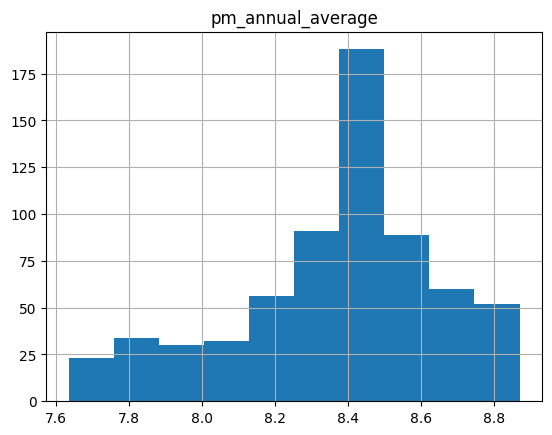

,STATEFP,COUNTYFP,TRACTCE,GEOID,GEOIDFQ,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry,ctfips,pm_annual_average,_merge
0,34,019,010100,34019010100,1400000US34019010100,101,Census Tract 101,G5020,S,81961274,337665,+40.6922260,-074.7734304,"POLYGON ((-74.84621 40.69693, -74.84621 40.697...",34019010100,7.831055,both
1,34,019,010201,34019010201,1400000US34019010201,102.01,Census Tract 102.01,G5020,S,45174599,354601,+40.7359760,-074.8996360,"POLYGON ((-74.96777 40.71203, -74.96773 40.712...",34019010201,7.840419,both
2,34,019,010202,34019010202,1400000US34019010202,102.02,Census Tract 102.02,G5020,S,38709857,349342,+40.7121662,-074.8744138,"POLYGON ((-74.92389 40.68185, -74.92369 40.681...",34019010202,7.836455,both
3,34,019,010300,34019010300,1400000US34019010300,103,Census Tract 103,G5020,S,7906403,31702,+40.7045232,-074.9500021,"POLYGON ((-74.98132 40.706, -74.98123 40.70608...",34019010300,7.957386,both
4,34,019,010400,34019010400,1400000US34019010400,104,Census Tract 104,G5020,S,55982620,378654,+40.6650355,-075.0119350,"POLYGON ((-75.11001 40.63892, -75.10989 40.639...",34019010400,8.105211,both


0


,count
_merge,
both,655
left_only,0
right_only,0


In [112]:
# plot histogram of the Annual pm2.5
# Normal distribution; the annual pm2.5 average range is 7.63-8.87
# If I map the pm 2.5 in one year, natural break classification may be appropriate
pm_annual2021.hist()
plt.show()

# Merge the annual PM2.5 average back with the spatial central Jersey map
# indicator=True so that the '_merge' column is created
merged_pm2021_central = pd.merge(central_jersey_map, pm_annual2021, left_on='GEOID', right_on='ctfips', how='outer', indicator=True)

# Inspect the first few rows of the merged data
merged_pm2021_central.head()

# check missing data
print(merged_pm2021_central['pm_annual_average'].isna().sum())          # count of missing/NaN income values
merged_pm2021_central['_merge'].value_counts()

In [113]:
# Prep for change from 2015 to 2021
# Merge 2015 and 2021 pm2.5 by county
merged_pm2015_2021_county = pd.merge(
    pm_annual2015_county, pm_annual2021_county,
    left_on='countyfips', right_on='countyfips',
    how='outer', indicator=True)
#merged_pm2015_2021_county
merged_pm2015_2021_county['decrease'] = merged_pm2015_2021_county['pm_annual_average_x'] - merged_pm2015_2021_county['pm_annual_average_y']
merged_pm2015_2021_county

# check missing data after merge
merged_pm2015_2021_county['_merge'].value_counts()


,countyfips,pm_annual_average_x,pm_annual_average_y,_merge,decrease
0,19,9.602433,8.148754,both,1.453679
1,21,9.394050,8.658543,both,0.735508
2,23,9.310595,8.469369,both,0.841225
3,25,8.553634,8.049327,both,0.504307
4,35,9.331942,8.244190,both,1.087752
5,39,9.656343,8.565195,both,1.091148


,count
_merge,
both,6
left_only,0
right_only,0


In [114]:
# Check the number of rows and unique IDs
print("Map rows:", len(central_jersey_map2015))
print("Unique map GEOIDs:", central_jersey_map2015["GEOID"].nunique())

print("PM rows:", len(pm_annual2015))
print("Unique PM GEOIDs:", pm_annual2015["ctfips"].nunique())

Map rows: 598
Unique map GEOIDs: 598
PM rows: 597
Unique PM GEOIDs: 597


array([[<Axes: title={'center': 'pm_annual_average'}>]], dtype=object)

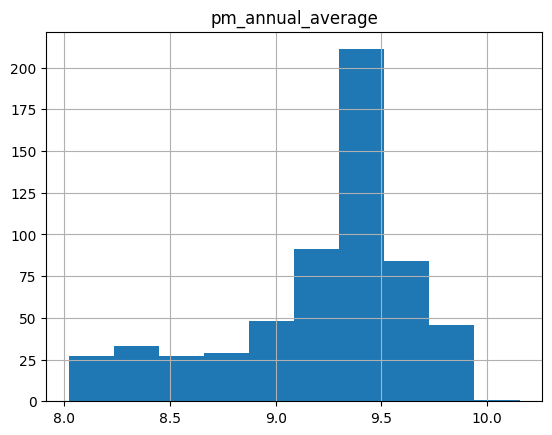

,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry,ctfips,pm_annual_average,_merge
0,34,019,010100,34019010100,101,Census Tract 101,G5020,S,81676243,447668,+40.6901688,-074.7716846,"POLYGON ((-74.84621 40.69693, -74.84621 40.697...",34019010100,9.278938,both
1,34,019,010200,34019010200,102,Census Tract 102,G5020,S,83933530,675377,+40.7263694,-074.8944081,"POLYGON ((-74.96767 40.71242, -74.9676 40.7125...",34019010200,9.420306,both
2,34,019,010300,34019010300,103,Census Tract 103,G5020,S,7915103,35569,+40.7045436,-074.9499493,"POLYGON ((-74.98128 40.7062, -74.981 40.70642,...",34019010300,9.612911,both
3,34,019,010400,34019010400,104,Census Tract 104,G5020,S,55913359,388455,+40.6650355,-075.0119350,"POLYGON ((-75.1099 40.63894, -75.10936 40.6394...",34019010400,9.839399,both
4,34,019,010500,34019010500,105,Census Tract 105,G5020,S,60902817,1317936,+40.5980387,-075.1241652,"POLYGON ((-75.19549 40.57872, -75.19548 40.578...",34019010500,10.153461,both


1


,count
_merge,
both,597
left_only,1
right_only,0


In [115]:
# plot 2015 histogram of the Annual pm2.5
# Normal distribution; the annual pm2.5 average range is 8-9.9
# If I map the pm 2.5 in one year, natural break classification may be appropriate
pm_annual2015.hist()
plt.show()


# Merge the annual PM2.5 average back with the spatial central Jersey map
# indicator=True so that the '_merge' column is created
merged_pm2015_central = pd.merge(central_jersey_map2015, pm_annual2015, left_on='GEOID', right_on='ctfips', how='outer', indicator=True)

# Inspect the first few rows of the merged data
merged_pm2015_central.head()

# check missing data
print(merged_pm2015_central['pm_annual_average'].isna().sum())          # count of missing/NaN income values
merged_pm2015_central['_merge'].value_counts()

In [117]:

# Convert countyfips in the county PM dataset to matched 3-digit string format (e.g., 19 -> '019')
merged_pm2015_2021_county['countyfips_str'] = merged_pm2015_2021_county['countyfips'].astype(str).str.zfill(3)


# Drop the existing '_merge' column if it exists to avoid conflicts when indicator=True
if '_merge' in merged_pm2015_2021_county.columns:
    merged_pm2015_2021_county = merged_pm2015_2021_county.drop(columns=['_merge'])

# merge the map with change of pm2.5
merged_pm2015_2021_central = pd.merge(
    central_jersey_map,
    merged_pm2015_2021_county,
    left_on='COUNTYFP',
    right_on='countyfips_str',
    how='outer',
    indicator=True
)

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

Text(3, 3, 'LINDEN')

Text(3, 3, 'LAMBERTVILLE')

...

Text(737.8055555555553, 0.5, '')

(-75.2610178, -73.8195382)

(40.0436949, 40.8232671)

(-75.2610178, -73.8195382)

(40.0436949, 40.8232671)

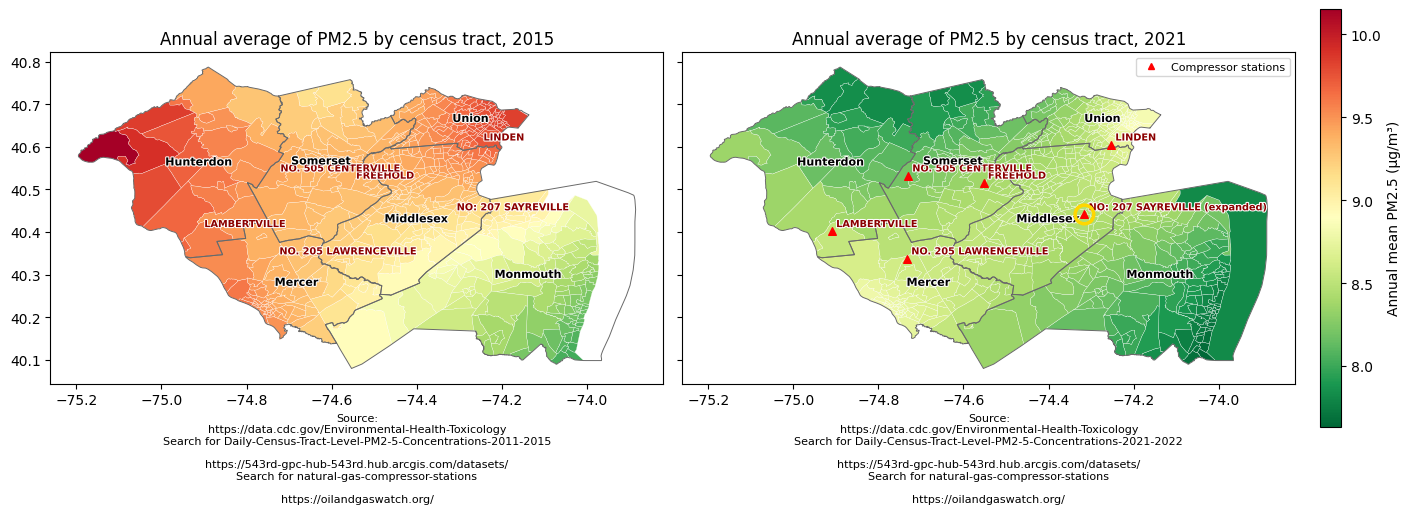

In [143]:
# Dissolve tracts up to county level
county_map = central_jersey_map.dissolve(by="COUNTYFP")

# Map county FIPS codes to county names
fips_to_name = {
    fips: name
    for name, fips in nj_county_fips_mapping.items()
    if fips in central_counties_fips
}

# Side-by-side maps
fig, axs = plt.subplots(
    1, 2, figsize=(14, 14),
    sharey=True,
    constrained_layout=True
)

# Plot 2015 PM2.5 map
merged_pm2015_central.plot(
    ax=axs[0],
    column="pm_annual_average",
    legend=False,
    cmap="RdYlGn_r",
    vmin=vmin_shared,
    vmax=vmax_shared,
    edgecolor="white",
    linewidth=0.2
)

# Plot 2021 PM2.5 map
merged_pm2021_central.plot(
    ax=axs[1],
    column="pm_annual_average",
    legend=False,
    cmap="RdYlGn_r",
    vmin=vmin_shared,
    vmax=vmax_shared,
    edgecolor="white",
    linewidth=0.2
)


# Overlay compressor stations on the 2021 map (axs[1])
compressors_in_region.plot(
    ax=axs[1],
    color="red",
    markersize=30,
    marker="^",
    zorder=5
)


# Add original station names to the 2015 map (left)
for idx, row in compressors_in_region.iterrows():
    station_name = str(row["NAME_left"])

    axs[0].annotate(
        station_name,
        xy=(row.geometry.x, row.geometry.y),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=7,
        color="darkred",
        fontweight="bold",
        path_effects=[
            path_effects.withStroke(
                linewidth=1.5,
                foreground="white"
            )
        ],
        zorder=4
    )

# Add station names to the 2021 map (right)
for idx, row in compressors_in_region.iterrows():
    station_name = str(row["NAME_left"])

    if "207" in station_name:
        station_name = f"{station_name} (expanded)"

    axs[1].annotate(
        station_name,
        xy=(row.geometry.x, row.geometry.y),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=7,
        color="darkred",
        fontweight="bold",
        path_effects=[
            path_effects.withStroke(
                linewidth=1.5,
                foreground="white"
            )
        ],
        zorder=4
    )

# Highlight Station 207 on the 2021 map
station_207 = compressors_in_region[
    compressors_in_region["NAME_left"].astype(str).str.contains("207", na=False)
]

axs[1].scatter(
    station_207.geometry.x,
    station_207.geometry.y,
    s=180,
    facecolors="none",
    edgecolors="gold",
    linewidths=2.5,
    zorder=6
)

point = Line2D(
    [0], [0],
    label="Compressor stations",
    marker="^",
    markersize=5,
    markeredgecolor="red",
    markerfacecolor="red",
    linestyle=""
)

axs[1].legend(handles=[point], loc="upper right", fontsize=8)


# Add county boundaries and labels to both maps
for ax in axs:
    county_map.boundary.plot(
        ax=ax,
        color="dimgray",
        linewidth=0.7,
        zorder=3
    )

    for fips, row in county_map.iterrows():
        point = row.geometry.representative_point()
        name = fips_to_name.get(fips, fips)

        ax.annotate(
            name,
            xy=(point.x, point.y),
            ha="center",
            va="center",
            fontsize=8,
            fontweight="bold",
            color="black",
            path_effects=[
                path_effects.withStroke(
                    linewidth=1.5,
                    foreground="white"
                )
            ],
            zorder=4
        )

# Titles and original source annotations
axs[0].set_title("Annual average of PM2.5 by census tract, 2015")
axs[0].set_xlabel(
    '''Source:
https://data.cdc.gov/Environmental-Health-Toxicology
Search for Daily-Census-Tract-Level-PM2-5-Concentrations-2011-2015\n
https://543rd-gpc-hub-543rd.hub.arcgis.com/datasets/
Search for natural-gas-compressor-stations\n
https://oilandgaswatch.org/''',
    fontsize=8
)

axs[1].set_title("Annual average of PM2.5 by census tract, 2021")
axs[1].set_xlabel(
    '''Source:
https://data.cdc.gov/Environmental-Health-Toxicology
Search for Daily-Census-Tract-Level-PM2-5-Concentrations-2021-2022\n
https://543rd-gpc-hub-543rd.hub.arcgis.com/datasets/
Search for natural-gas-compressor-stations\n
https://oilandgaswatch.org/''',
    fontsize=8
)

for ax in axs:
    ax.set_ylabel("")
    ax.set_aspect("equal")

# Match geographic extents
xmin = min(ax.get_xlim()[0] for ax in axs)
xmax = max(ax.get_xlim()[1] for ax in axs)
ymin = min(ax.get_ylim()[0] for ax in axs)
ymax = max(ax.get_ylim()[1] for ax in axs)

for ax in axs:
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

# Create one shared colorbar
norm = mpl.colors.Normalize(
    vmin=vmin_shared,
    vmax=vmax_shared
)
sm = mpl.cm.ScalarMappable(norm=norm, cmap="RdYlGn_r")
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axs,
    orientation="vertical",
    fraction=0.035,
    pad=0.02,
    shrink=0.3
)
cbar.set_label("Annual mean PM2.5 (μg/m³)")

plt.show()



In 2015, annual mean PM2.5 concentrations across census tracts ranged from 8.02 to 10.15 μg/m³. In 2021, concentrations ranged from 7.63 to 8.87 μg/m³. Both maps use a shared color scale ranging from 7.63 μg/m³ (dark green) to 10.15 μg/m³ (dark red), allowing the spatial patterns and concentration levels to be compared across years. The scale represents a continuous gradient, with colors transitioning from lower to higher concentrations.

Census tract boundaries changed between the two study years. To account for these geographic differences, the 2015 PM2.5 data were joined to the 2015 TIGER/Line shapefile, while the 2021 PM2.5 data were joined to the 2021 PM2.5 estimates using the selected corresponding tract geography. One census tract in Monmouth County was missing from the 2015 PM2.5 dataset, whereas all census tracts in the study area were represented in the 2021 dataset. These differences should be considered when interpreting changes between the maps.

The maps suggest a change in the spatial distribution of higher PM2.5 concentrations between 2015 and 2021. In 2015, the highest concentrations were observed in parts of Union and Hunterdon counties. By 2021, areas with relatively higher concentrations were observed in parts of Union, Mercer, and Middlesex counties. Although the overall mean concentration across the study region decreased, the locations of relatively higher concentrations shifted. These patterns describe changes in PM2.5 distribution and do not establish whether compressor station operations contributed to the observed differences.

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

Text(-74.912931448437, 40.563423, 'Hunterdon')

Text(0, 6, '-1.454')

Text(-74.68257063368384, 40.2804615, 'Mercer')

Text(0, 6, '-0.736')

...

Text(3, 3, 'FREEHOLD')

Text(3, 3, 'NO. 505 CENTERVILLE')

Text(0.5, 1.0, 'Decrease in Annual Average PM2.5 by County, 2015–2021')

Text(0.45, 0.3, 'Source: CDC, Daily Census Tract-Level PM2.5 Concentrations\n    https://data.cdc.gov/Environmental-Health-Toxicology\n\n    543rd::natural-gas-compressor-stations\n    https://543rd-gpc-hub-543rd.hub.arcgis.com/datasets/\n\n    ')

Text(78.97222222222221, 0.5, '')

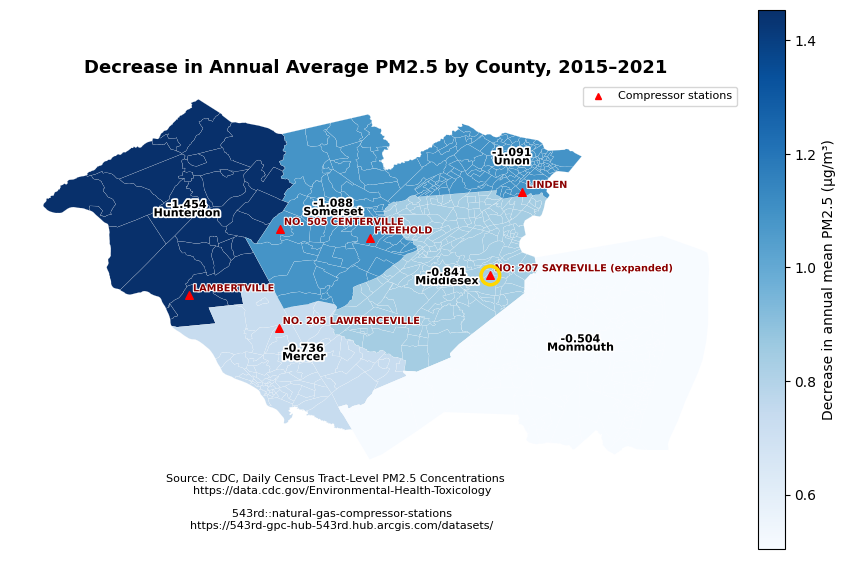

In [145]:
# Create a single county-level map
fig, ax = plt.subplots(figsize=(10, 10))

# Plot county-level PM2.5 change (no census-tract boundaries)
merged_pm2015_2021_central.plot(
    ax=ax,
    column="decrease",
    legend=False,
    cmap="Blues",
    edgecolor="white",
    linewidth=0.1
)

# Add one county name per county
for fips, row in county_map.iterrows():
    point = row.geometry.representative_point()
    name = fips_to_name.get(fips, fips)

    ax.annotate(
        name,
        xy=(point.x, point.y),
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold",
        color="black",
        path_effects=[
            path_effects.withStroke(
                linewidth=2.5,
                foreground="white"
            )
        ],
        zorder=4
    )

    # Get the county's change value
    change = merged_pm2015_2021_central.loc[
        merged_pm2015_2021_central["COUNTYFP"] == fips,
        "decrease"
    ].iloc[0]

    # Change value above county name, with a minus sign
    ax.annotate(
        f"-{abs(change):.3f}",
        xy=(point.x, point.y),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold",
        color="black",
        path_effects=[
            path_effects.withStroke(
                linewidth=2.5,
                foreground="white"
            )
        ],
        zorder=4
    )

# Overlay compressor stations
compressors_in_region.plot(
    ax=ax,
    color="red",
    markersize=30,
    marker="^",
    zorder=5
)


# Add station names
for idx, row in compressors_in_region.iterrows():
    station_name = row["NAME_left"]

    if "207" in str(station_name):
        station_name = f"{station_name} (expanded)"

    ax.annotate(
        station_name,
        xy=(row.geometry.x, row.geometry.y),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=7,
        color="darkred",
        fontweight="bold",
        path_effects=[
            path_effects.withStroke(
                linewidth=1.5,
                foreground="white"
            )
        ],
        zorder=4
    )

# Highlight Station 207 on the 2021 map
station_207 = compressors_in_region[
    compressors_in_region["NAME_left"].astype(str).str.contains("207", na=False)
]

ax.scatter(
    station_207.geometry.x,
    station_207.geometry.y,
    s=180,
    facecolors="none",
    edgecolors="gold",
    linewidths=2.5,
    zorder=6
)

ax.set_title(
    "Decrease in Annual Average PM2.5 by County, 2015–2021",
    fontsize=13,
    fontweight="bold"
)

# Source annotation below the map
fig.text(
    0.45, 0.30,
    '''Source: CDC, Daily Census Tract-Level PM2.5 Concentrations
    https://data.cdc.gov/Environmental-Health-Toxicology\n
    543rd::natural-gas-compressor-stations
    https://543rd-gpc-hub-543rd.hub.arcgis.com/datasets/\n
    ''',
    ha="center",
    va="top",
    fontsize=8
)

ax.set_ylabel("")
ax.set_axis_off()
ax.set_aspect("equal")

# Shared color scale for this map
norm = mpl.colors.Normalize(
    vmin=merged_pm2015_2021_central["decrease"].min(),
    vmax=merged_pm2015_2021_central["decrease"].max()
)
sm = mpl.cm.ScalarMappable(norm=norm, cmap="Blues")
sm.set_array([])

cbar = fig.colorbar(
    sm, ax=ax,
    fraction=0.035, pad=0.02, shrink=0.7
)
cbar.set_label("Decrease in annual mean PM2.5 (μg/m³)")

# Compressor station legend
station_legend = Line2D(
    [0], [0],
    label="Compressor stations",
    marker="^",
    markersize=5,
    markeredgecolor="red",
    markerfacecolor="red",
    linestyle=""
)
ax.legend(handles=[station_legend], loc="upper right", fontsize=8)

plt.show()

The change map summarizes the difference in annual mean PM2.5 concentrations between 2015 and 2021 across the study area. The change is calculated as the 2015 concentration minus the 2021 concentration, so the values indicate a decrease in PM2.5. This map helps identify counties where concentrations declined more substantially and areas where concentrations increased or declined less.

Together, the two annual maps and the change map show that an overall reduction in PM2.5 does not necessarily mean that all locations experienced the same degree of improvement.

In [95]:
# Load the 2025 csv of CDC PLACES (DATA FROM 2023)
!wget -O cdc_places_tract_data.csv "https://github.com/4xuanzhou/GIS/releases/download/v1.0/PLACES__Census_Tract_Data_.GIS_Friendly_Format._2025_release_20260917.csv"

cdc0 = pd.read_csv("cdc_places_tract_data.csv")
#cdc0.columns
#cdc0.head()

# 2020 (BRFSS DATA FROM 2018)
# This is just New Jersey
!wget -O cdc_places_tract_data_2020.csv "https://github.com/4xuanzhou/GIS/releases/download/v1.1/PLACES__Census_Tract_Data_.GIS_Friendly_Format._2020_release_20261015.csv"

cdc2020 = pd.read_csv("cdc_places_tract_data_2020.csv")
cdc2020.columns
cdc2020.head()
#cdc2020['StateAbbr'].unique()


--2026-10-15 14:27:43--  https://github.com/4xuanzhou/GIS/releases/download/v1.0/PLACES__Census_Tract_Data_.GIS_Friendly_Format._2025_release_20260917.csv
Resolving github.com (github.com)... 20.29.134.23
Connecting to github.com (github.com)|20.29.134.23|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/1356505801/b419107b-3bd7-4326-b976-0e798968642d?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-10-15T15%3A16%3A46Z&rscd=attachment%3B+filename%3DPLACES__Census_Tract_Data_.GIS_Friendly_Format._2025_release_20260917.csv&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-10-15T14%3A16%3A01Z&ske=2026-10-15T15%3A16%3A46Z&sks=b&skv=2018-11-09&sig=WHTyQu8XrIE4cVxzKtAUHKezwoCA7HsoskZUyau7q5Q%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tI

Index(['StateAbbr', 'StateDesc', 'CountyName', 'CountyFIPS', 'TractFIPS',
       'TotalPopulation', 'ACCESS2_CrudePrev', 'ACCESS2_Crude95CI',
       'ARTHRITIS_CrudePrev', 'ARTHRITIS_Crude95CI', 'BINGE_CrudePrev',
       'BINGE_Crude95CI', 'BPHIGH_CrudePrev', 'BPHIGH_Crude95CI',
       'BPMED_CrudePrev', 'BPMED_Crude95CI', 'CANCER_CrudePrev',
       'CANCER_Crude95CI', 'CASTHMA_CrudePrev', 'CASTHMA_Crude95CI',
       'CERVICAL_CrudePrev', 'CERVICAL_Crude95CI', 'CHD_CrudePrev',
       'CHD_Crude95CI', 'CHECKUP_CrudePrev', 'CHECKUP_Crude95CI',
       'CHOLSCREEN_CrudePrev', 'CHOLSCREEN_Crude95CI',
       'COLON_SCREEN_CrudePrev', 'COLON_SCREEN_Crude95CI', 'COPD_CrudePrev',
       'COPD_Crude95CI', 'COREM_CrudePrev', 'COREM_Crude95CI',
       'COREW_CrudePrev', 'COREW_Crude95CI', 'CSMOKING_CrudePrev',
       'CSMOKING_Crude95CI', 'DENTAL_CrudePrev', 'DENTAL_Crude95CI',
       'DIABETES_CrudePrev', 'DIABETES_Crude95CI', 'HIGHCHOL_CrudePrev',
       'HIGHCHOL_Crude95CI', 'KIDNEY_CrudePrev',

,StateAbbr,StateDesc,CountyName,CountyFIPS,TractFIPS,TotalPopulation,ACCESS2_CrudePrev,ACCESS2_Crude95CI,ARTHRITIS_CrudePrev,ARTHRITIS_Crude95CI,...,OBESITY_Crude95CI,PHLTH_CrudePrev,PHLTH_Crude95CI,SLEEP_CrudePrev,SLEEP_Crude95CI,STROKE_CrudePrev,STROKE_Crude95CI,TEETHLOST_CrudePrev,TEETHLOST_Crude95CI,Geolocation
0,NJ,New Jersey,Atlantic,34001,34001000100,2417,27.5,"(24.3, 30.5)",23.0,"(22.1, 23.7)",...,"(35.6, 37.7)",18.8,"(17.6, 20.0)",45.5,"(44.1, 47.0)",4.0,"( 3.7, 4.3)",25.8,"(19.1, 32.6)",POINT (-74.46331472 39.35645141)
1,NJ,New Jersey,Atlantic,34001,34001000200,3202,19.2,"(16.8, 22.0)",25.4,"(24.2, 26.6)",...,"(27.6, 29.5)",15.2,"(13.4, 16.4)",40.1,"(38.2, 41.5)",4.0,"( 3.5, 4.5)",17.1,"(11.0, 24.9)",POINT (-74.46202033 39.34685825)
2,NJ,New Jersey,Atlantic,34001,34001000300,4373,27.7,"(23.3, 31.6)",19.1,"(18.3, 19.8)",...,"(30.6, 32.8)",16.4,"(14.8, 18.8)",44.3,"(42.7, 45.8)",3.2,"( 2.9, 3.4)",20.5,"(15.0, 25.7)",POINT (-74.45425828 39.35349166)
3,NJ,New Jersey,Atlantic,34001,34001000400,2606,23.0,"(20.5, 25.8)",27.3,"(26.4, 28.0)",...,"(32.5, 34.4)",19.2,"(18.2, 20.9)",43.8,"(42.8, 45.0)",4.9,"( 4.4, 5.4)",23.8,"(17.3, 31.2)",POINT (-74.45000121 39.35093303)
4,NJ,New Jersey,Atlantic,34001,34001000500,3503,32.9,"(29.6, 36.9)",20.0,"(19.2, 20.7)",...,"(31.3, 33.7)",18.9,"(17.8, 19.8)",47.0,"(45.6, 48.6)",3.7,"( 3.4, 4.0)",27.3,"(22.1, 32.5)",POINT (-74.44732359 39.35676781)


In [97]:
# Select the New Jersey observations from CDC Places large dataset
cdc_nj = cdc0[cdc0['StateAbbr']=='NJ']
#cdc_nj.head()

# Select central NJ counties
# since these are places of interest in this study
cdc_central_nj = cdc_nj[cdc_nj['CountyName'].isin(central_counties)]
#cdc_central_nj.head()
#cdc_central_nj.columns
mh_asthma = cdc_central_nj[['StateAbbr', 'StateDesc', 'CountyName', 'CountyFIPS', 'TractFIPS', 'TotalPopulation', 'TotalPop18plus', 'CASTHMA_CrudePrev', 'CASTHMA_Crude95CI', 'MHLTH_CrudePrev', 'MHLTH_Crude95CI']]
#mh_asthma.head()
# check unique "CountyName" in cdc_central_nj
# cdc_central_nj['CountyName'].unique()


# cdc2020
# cdc2020.columns
central_counties_fips
cdc2020_central_nj = cdc2020[
    cdc2020["TractFIPS"].astype(str).str.zfill(11).str[2:5]
    .isin(central_counties_fips)
]
cdc2020_central_nj['CountyFIPS'].unique()

['019', '021', '023', '025', '035', '039']

array([34019, 34021, 34023, 34025, 34035, 34039])

In [98]:
# Convert TractFIPS to string; make GEOID have 11 digits
mh_asthma['TractFIPS'] = mh_asthma['TractFIPS'].astype(str).str.zfill(11)

# Make sure filtered_map's GEOID is also a string for a clean match
central_jersey_map['GEOID'] = central_jersey_map['GEOID'].astype(str)

# Merge
a1 = pd.merge(central_jersey_map, mh_asthma, left_on='GEOID', right_on='TractFIPS', how='outer', indicator=True)

# Convert cdc2020_central_nj TractFIPS to a matching string format with leading zeros
cdc2020_central_nj['TractFIPS'] = cdc2020_central_nj['TractFIPS'].astype(str).str.zfill(11)


# Merge cdc places 2020 with central_jersey_map2015
merged_cdc2020_map2015 = pd.merge(central_jersey_map2015, cdc2020_central_nj, left_on='GEOID', right_on='TractFIPS', how='outer', indicator=True)
merged_cdc2020_map2015.head()

/tmp/ipykernel_2211/3379970073.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mh_asthma['TractFIPS'] = mh_asthma['TractFIPS'].astype(str).str.zfill(11)
/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2011: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/tmp/ipykernel_2211/3379970073.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in

,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,...,PHLTH_CrudePrev,PHLTH_Crude95CI,SLEEP_CrudePrev,SLEEP_Crude95CI,STROKE_CrudePrev,STROKE_Crude95CI,TEETHLOST_CrudePrev,TEETHLOST_Crude95CI,Geolocation,_merge
0,34,019,010100,34019010100,101,Census Tract 101,G5020,S,81676243,447668,...,9.6,"( 8.9, 10.3)",31.5,"(30.5, 32.7)",2.5,"( 2.3, 2.7)",5.3,"( 3.8, 7.1)",POINT (-74.77848345 40.69538675),both
1,34,019,010200,34019010200,102,Census Tract 102,G5020,S,83933530,675377,...,10.5,"( 9.5, 11.5)",33.3,"(31.7, 34.7)",2.5,"( 2.3, 2.7)",7.1,"( 5.0, 9.7)",POINT (-74.8886928 40.72752023),both
2,34,019,010300,34019010300,103,Census Tract 103,G5020,S,7915103,35569,...,11.8,"(10.9, 13.2)",36.1,"(34.7, 37.8)",2.6,"( 2.3, 2.8)",9.8,"( 6.9, 13.2)",POINT (-74.95191471 40.70363024),both
3,34,019,010400,34019010400,104,Census Tract 104,G5020,S,55913359,388455,...,10.2,"( 9.6, 11.6)",34.0,"(32.6, 35.8)",2.3,"( 2.1, 2.5)",6.6,"( 5.0, 8.4)",POINT (-75.01277137 40.66813741),both
4,34,019,010500,34019010500,105,Census Tract 105,G5020,S,60902817,1317936,...,11.4,"(10.0, 13.1)",33.9,"(31.9, 35.7)",2.7,"( 2.4, 3.1)",8.2,"( 4.6, 12.4)",POINT (-75.12214605 40.59645544),both


In [ ]:
# check missing data
a1['_merge'].value_counts()
#a1.head()

print(a1['CASTHMA_CrudePrev'].isna().sum())          # count of missing/NaN ASTHMA
print((a1['CASTHMA_CrudePrev'] < 0).sum())           # count of suppressed placeholder codes

print(a1['MHLTH_CrudePrev'].isna().sum())          # count of missing/NaN ASTHMA
print((a1['MHLTH_CrudePrev'] < 0).sum())           # count of suppressed placeholder codes

#check missing data for the 2020 cdc merged with map2015
merged_cdc2020_map2015['_merge'].value_counts()

,count
_merge,
both,653
left_only,2
right_only,0


2
0
2
0


,count
_merge,
both,596
left_only,2
right_only,0


#### Prevalence of current asthma among adults

The data source of prevalence of current asthma among adults is CDC PLACES (Centers for Disease Control and Prevention, 2025). The histgrams show the distributions of asthma prevalence across census tracts are approximately normal.

<Axes: >

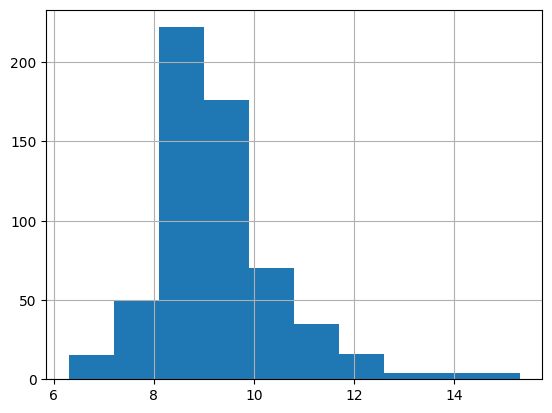

<Axes: >

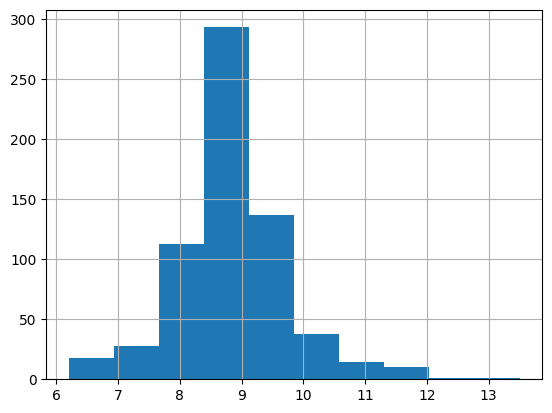

In [ ]:
# histgram of cdc places 2020 asthma data (2018 brfss)
# Normal distribution
cdc2020_central_nj['CASTHMA_CrudePrev'].hist()
plt.show()

# histgram of cdc places 2025 asthma data (2023 brfss)
# Normal distribution
mh_asthma['CASTHMA_CrudePrev'].hist()
plt.show()

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

Text(0.5, 1.0, 'Model-Based Estimate of Crude Prevalence\nof Current Asthma Among Adults, 2018')

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

Text(0.5, 1.0, 'Model-Based Estimate of Crude Prevalence\nof Current Asthma Among Adults, 2023')

<Axes: title={'center': 'Model-Based Estimate of Crude Prevalence\nof Current Asthma Among Adults, 2018'}, xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

...

Text(-74.13849262955802, 40.299041, 'Monmouth')

Text(-74.62522443350142, 40.5658995, 'Somerset')

Text(-74.27350858295, 40.665786499999996, 'Union')

Text(0.25, 0.27, 'Source: CDC PLACES 2020\nhttps://data.cdc.gov/500-Cities-Places\nSearch for PLACES-Census-Tract-Data-GIS-Friendly-Format-2020')

Text(0.68, 0.27, 'Source: CDC PLACES 2025\nhttps://data.cdc.gov/500-Cities-Places\nSearch for PLACES-Census-Tract-Data-GIS-Friendly-Format-2025')

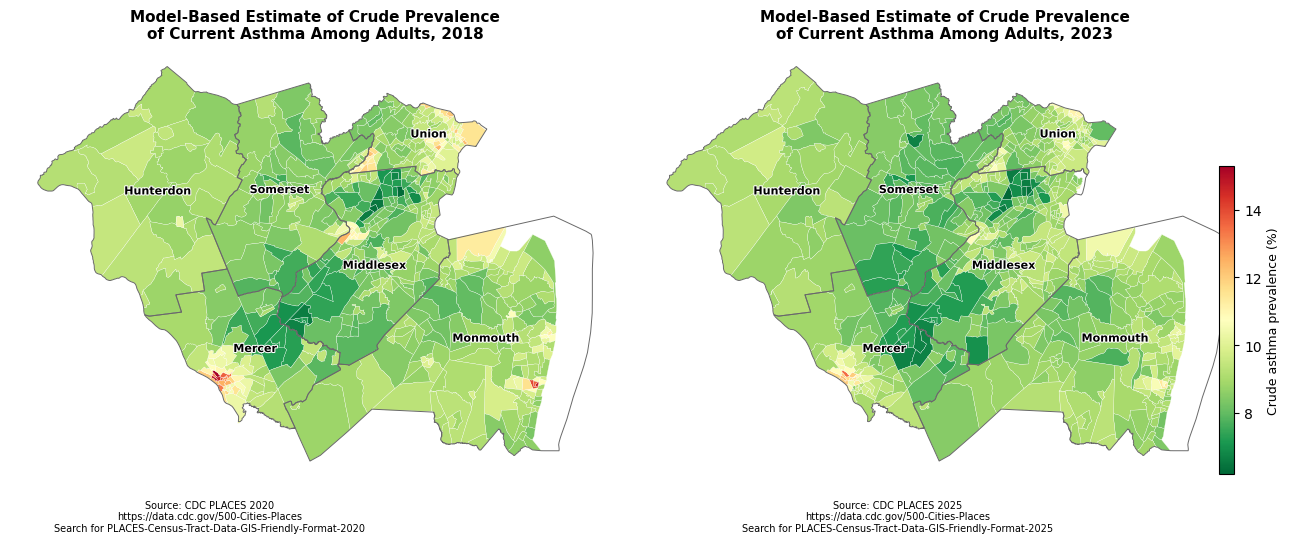

In [ ]:
# Shared color scale across both years
vmin = min(
    merged_cdc2020_map2015["CASTHMA_CrudePrev"].min(),
    a1["CASTHMA_CrudePrev"].min()
)
vmax = max(
    merged_cdc2020_map2015["CASTHMA_CrudePrev"].max(),
    a1["CASTHMA_CrudePrev"].max()
)

cmap = "RdYlGn_r"
norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)

# Dissolve tracts up to county level
county_map = central_jersey_map.dissolve(by="COUNTYFP")

# Map county FIPS codes to county names
fips_to_name = {
    fips: name
    for name, fips in nj_county_fips_mapping.items()
    if fips in central_counties_fips
}

# Create side-by-side maps
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# 2018 map
merged_cdc2020_map2015.plot(
    ax=axes[0],
    column="CASTHMA_CrudePrev",
    cmap=cmap,
    norm=norm,
    edgecolor="white",
    linewidth=0.2,
    legend=False
)

axes[0].set_title(
    "Model-Based Estimate of Crude Prevalence\n"
    "of Current Asthma Among Adults, 2018",
    fontsize=11,
    fontweight="bold"
)

# 2023 map
a1.plot(
    ax=axes[1],
    column="CASTHMA_CrudePrev",
    cmap=cmap,
    norm=norm,
    edgecolor="white",
    linewidth=0.2,
    legend=False
)

axes[1].set_title(
    "Model-Based Estimate of Crude Prevalence\n"
    "of Current Asthma Among Adults, 2023",
    fontsize=11,
    fontweight="bold"
)

# Remove axis borders
for ax in axes:
    ax.set_axis_off()
    ax.set_aspect("equal")

# Add county boundaries and labels to both maps
for ax in axes:
    county_map.boundary.plot(
        ax=ax,
        color="dimgray",
        linewidth=0.7,
        zorder=3
    )

    for fips, row in county_map.iterrows():
        point = row.geometry.representative_point()
        name = fips_to_name.get(fips, fips)

        ax.annotate(
            name,
            xy=(point.x, point.y),
            ha="center",
            va="center",
            fontsize=8,
            fontweight="bold",
            color="black",
            path_effects=[
                path_effects.withStroke(
                    linewidth=1.5,
                    foreground="white"
                )
            ],
            zorder=4
        )

# One shared colorbar for both maps
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes,
    orientation="vertical",
    fraction=0.025,
    pad=0.02,
    shrink=0.5
)
cbar.set_label(
    "Crude asthma prevalence (%)",
    fontsize=9
)

# Source annotations below each map
fig.text(
    0.25, 0.27,
    "Source: CDC PLACES 2020\n"
    "https://data.cdc.gov/500-Cities-Places\n"
    "Search for PLACES-Census-Tract-Data-GIS-Friendly-Format-2020",
    ha="center",
    va="top",
    fontsize=7
)

fig.text(
    0.68, 0.27,
    "Source: CDC PLACES 2025\n"
    "https://data.cdc.gov/500-Cities-Places\n"
    "Search for PLACES-Census-Tract-Data-GIS-Friendly-Format-2025",
    ha="center",
    va="top",
    fontsize=7
)

plt.subplots_adjust(
    wspace=0.03,
    bottom=0.28,
    top=0.85
)

plt.show()

Some census tracts in the Middlesex and Mercer Counties had some extremely high asthma prevalence in 2018. The overall asthma prevalence decreased in 2023. However, some census tracts in Mercer and Middlesex remained higher than other communities.

,COUNTYFP,Asthma 2018,Asthma 2023,Asthma change
0,019,9.150000,8.970000,-0.180000
1,021,10.180519,9.273810,-0.906710
2,023,8.512571,8.539267,0.026696
3,025,9.298592,9.027922,-0.270669
4,035,8.714706,8.225676,-0.489030
5,039,9.865741,9.199167,-0.666574


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

Text(0.5, 1.0, 'Change in Mean Asthma Prevalence by County, 2018–2023')

<Axes: title={'center': 'Change in Mean Asthma Prevalence by County, 2018–2023'}, xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

Text(3, 3, 'LINDEN')

...

Text(0, 8, '-0.271')

Text(-74.62522443350142, 40.5658995, 'Somerset')

Text(0, 8, '-0.489')

Text(-74.27350858295, 40.665786499999996, 'Union')

Text(0, 8, '-0.667')

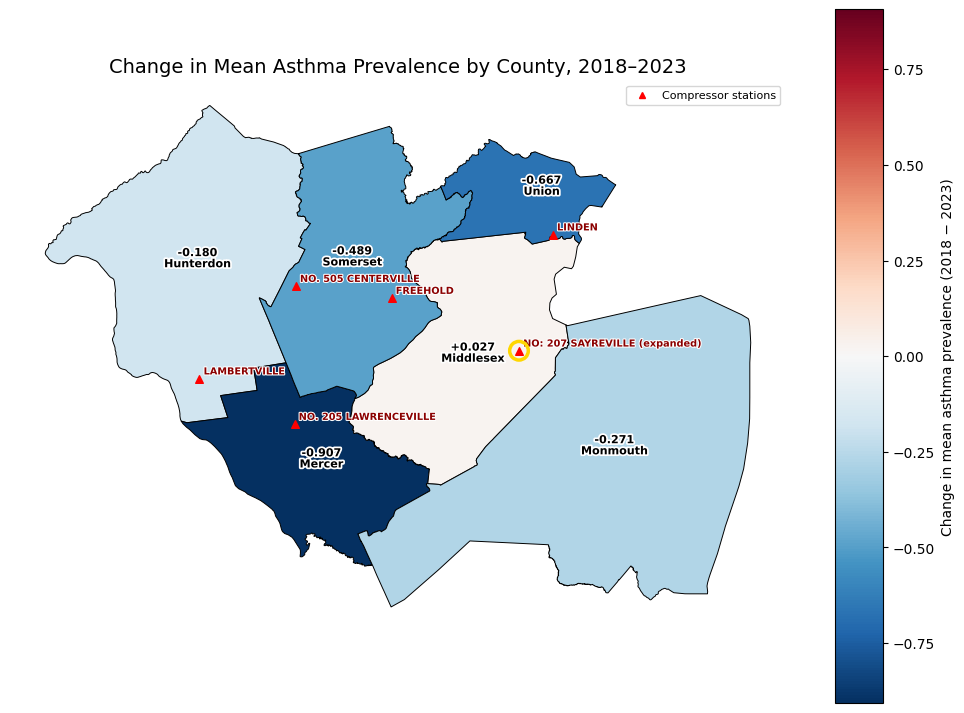

In [152]:



# Prepare the asthma data for each year
asthma_2018 = merged_cdc2020_map2015[
    ["GEOID", "COUNTYFP", "CASTHMA_CrudePrev"]
].copy()

asthma_2023 = a1[
    ["GEOID", "COUNTYFP", "CASTHMA_CrudePrev"]
].copy()

# Aggregate tract-level asthma prevalence to counties
county_asthma_2018 = (
    asthma_2018
    .groupby("COUNTYFP")["CASTHMA_CrudePrev"]
    .mean()
    .rename("Asthma 2018")
)

county_asthma_2023 = (
    asthma_2023
    .groupby("COUNTYFP")["CASTHMA_CrudePrev"]
    .mean()
    .rename("Asthma 2023")
)

# Combine the county-level estimates
county_asthma = pd.concat(
    [county_asthma_2018, county_asthma_2023],
    axis=1,
    join="inner"
).reset_index()

# Calculate the change in asthma prevalence
# decrease from 2018 to 2023
county_asthma["Asthma change"] = (
    county_asthma["Asthma 2023"] -
    county_asthma["Asthma 2018"]
)

county_asthma

# Join the results to your county map
county_asthma_map = county_map.reset_index().merge(
    county_asthma,
    on="COUNTYFP",
    how="left"
)



from matplotlib.colors import TwoSlopeNorm


# Set a symmetric color scale centered at zero
max_abs_change = county_asthma_map["Asthma change"].abs().max()

norm = TwoSlopeNorm(
    vmin=-max_abs_change,
    vcenter=0,
    vmax=max_abs_change
)

# Plot the county-level change map
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

county_asthma_map.plot(
    column="Asthma change",
    cmap="RdBu_r",
    norm=norm,
    legend=True,
    ax=ax,
    edgecolor="black",
    linewidth=0.7,
    missing_kwds={"color": "lightgrey", "label": "No data"},
    legend_kwds={
        "label": "Change in mean asthma prevalence (2018 − 2023)"
    }
)

ax.set_title(
    "Change in Mean Asthma Prevalence by County, 2018–2023",
    fontsize=14
)
ax.set_axis_off()

# Overlay compressor stations
compressors_in_region.plot(
    ax=ax,
    color="red",
    markersize=30,
    marker="^",
    zorder=5
)

# Add station names
for idx, row in compressors_in_region.iterrows():
    station_name = str(row["NAME_left"])

    if "207" in station_name:
        station_name = f"{station_name} (expanded)"

    ax.annotate(
        station_name,
        xy=(row.geometry.x, row.geometry.y),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=7,
        color="darkred",
        fontweight="bold",
        path_effects=[
            path_effects.withStroke(
                linewidth=1.5,
                foreground="white"
            )
        ],
        zorder=7
    )

# Highlight Station 207 with a gold circle
station_207 = compressors_in_region[
    compressors_in_region["NAME_left"]
    .astype(str)
    .str.contains("207", na=False)
]

ax.scatter(
    station_207.geometry.x,
    station_207.geometry.y,
    s=180,
    facecolors="none",
    edgecolors="gold",
    linewidths=2.5,
    zorder=8
)

# Compressor station legend
station_legend = Line2D(
    [0], [0],
    label="Compressor stations",
    marker="^",
    markersize=5,
    markeredgecolor="red",
    markerfacecolor="red",
    linestyle=""
)

ax.legend(
    handles=[station_legend],
    loc="upper right",
    fontsize=8
)

# Add county names and signed asthma change values
for _, row in county_asthma_map.iterrows():
    point = row.geometry.representative_point()
    fips = row["COUNTYFP"]
    name = fips_to_name.get(fips, fips)
    change = row["Asthma change"]

    # County name
    ax.annotate(
        name,
        xy=(point.x, point.y),
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold",
        color="black",
        path_effects=[
            path_effects.withStroke(
                linewidth=2.5,
                foreground="white"
            )
        ],
        zorder=4
    )

    # Change value above county name
    if pd.notna(change):
        ax.annotate(
            f"{change:+.3f}",
            xy=(point.x, point.y),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            va="center",
            fontsize=8,
            fontweight="bold",
            color="black",
            path_effects=[
                path_effects.withStroke(
                    linewidth=2.5,
                    foreground="white"
                )
            ],
            zorder=4
        )

plt.tight_layout()
plt.show()




The change of Asthma prevalence from 2018 to 2023 demonstrates that the only county that has an increase in asthma prevalence is Middlesex. It increased by .027. Other counties saw a decrease in asthma prevalence. This is something to consider further, because Middlesex saw Compressor Station 207's expansion in this time frame.

####PM 2.5 and Asthma Prevalence

<Axes: xlabel='PM2.5 2015', ylabel='Asthma 2018'>

Text(0.5, 1.0, 'PM2.5 2015 vs. Asthma 2018')

Text(0.5, 0, 'PM2.5 2015')

Text(0, 0.5, 'Asthma 2018')

Text(0.05, 0.95, 'Pearson r = 0.08')

<Axes: xlabel='PM2.5 2021', ylabel='Asthma 2023'>

Text(0.5, 1.0, 'PM2.5 2021 vs. Asthma 2023')

Text(0.5, 0, 'PM2.5 2021')

Text(0, 0.5, 'Asthma 2023')

Text(0.05, 0.95, 'Pearson r = 0.14')

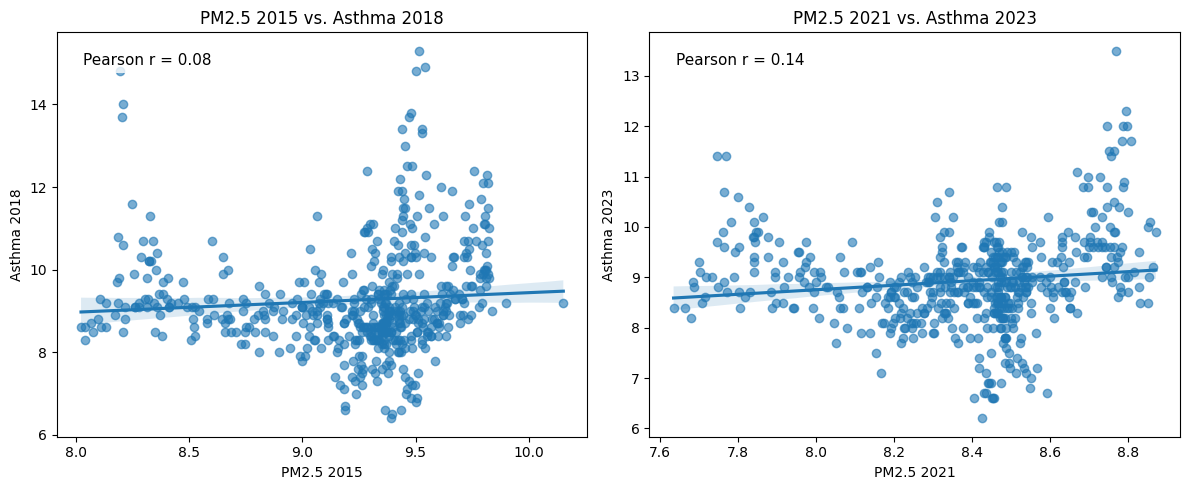

In [ ]:
# Select and rename asthma and PM2.5 variables
asthma_2018 = merged_cdc2020_map2015[
    ["GEOID", "CASTHMA_CrudePrev"]
].rename(columns={"CASTHMA_CrudePrev": "Asthma 2018"})

asthma_2023 = a1[
    ["GEOID", "CASTHMA_CrudePrev"]
].rename(columns={"CASTHMA_CrudePrev": "Asthma 2023"})

pm25_2015 = merged_pm2015_central[
    ["GEOID", "pm_annual_average"]
].rename(columns={"pm_annual_average": "PM2.5 2015"})

pm25_2021 = merged_pm2021_central[
    ["GEOID", "pm_annual_average"]
].rename(columns={"pm_annual_average": "PM2.5 2021"})

# Merge datasets by census tract
correlation_data = (
    asthma_2018
    .merge(asthma_2023, on="GEOID", how="inner")
    .merge(pm25_2015, on="GEOID", how="inner")
    .merge(pm25_2021, on="GEOID", how="inner")
)

# Remove rows with missing values in any of the four measures
correlation_data = correlation_data.dropna(
    subset=["Asthma 2018", "Asthma 2023", "PM2.5 2015", "PM2.5 2021"]
)

# Create two scatter plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

pairs = [
    ("PM2.5 2015", "Asthma 2018"),
    ("PM2.5 2021", "Asthma 2023")
]

for ax, (x, y) in zip(axes, pairs):
    # Calculate Pearson correlation
    r = correlation_data[[x, y]].corr().iloc[0, 1]

    # Plot scatter points and regression line
    sns.regplot(
        data=correlation_data,
        x=x,
        y=y,
        ax=ax,
        scatter_kws={"alpha": 0.6}
    )

    # Add title and axis labels
    ax.set_title(f"{x} vs. {y}")
    ax.set_xlabel(x)
    ax.set_ylabel(y)

    # Add correlation coefficient
    ax.text(
        0.05, 0.95,
        f"Pearson r = {r:.2f}",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=11,
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none")
    )

plt.tight_layout()
plt.show()


The scatter plots showed weak positive correlations between annual average PM2.5 concentrations and crude asthma prevalence across census tracts. The correlation was 0.08 for the 2015 PM2.5 and 2018 asthma comparison and 0.14 for the 2021 PM2.5 and 2023 asthma comparison. This increase in correlation strength needs further investigation.

#### References

543rd Geospatial Planning Cell. (2021). *Natural gas compressor stations* [Data set]. ArcGIS. https://543rd-gpc-hub-543rd.hub.arcgis.com/datasets/543rd::natural-gas-compressor-stations/explore

Anthropic. (2026). *Claude (Sonnet 5)* [Large language model]. https://claude.ai

Blinn, H. N., Utz, R. M., Greiner, L. H., & Brown, D. R. (2020). Exposure assessment of adults living near unconventional oil and natural gas development and reported health symptoms in southwest Pennsylvania, USA. *PLOS ONE, 15*(8), e0237325. https://doi.org/10.1371/journal.pone.0237325

Centers for Disease Control and Prevention. (2025). *PLACES: Census tract data (GIS friendly format), 2025 release* [Data set]. https://data.cdc.gov/500-Cities-Places/PLACES-Census-Tract-Data-GIS-Friendly-Format-2025-/yjkw-uj5s/about_data

Centers for Disease Control and Prevention. (2026). *Daily census tract-level PM2.5 concentrations, 2011–2015* [Data set] https://data.cdc.gov/Environmental-Health-Toxicology/Daily-Census-Tract-Level-PM2-5-Concentrations-2011/qjxm-7fny/about_data

Centers for Disease Control and Prevention. (2026). *Daily census tract-level PM2.5 concentrations, 2021–2022* [Data set] https://data.cdc.gov/Environmental-Health-Toxicology/Daily-Census-Tract-Level-PM2-5-Concentrations-2021/vpk8-vfhm

Environmental Integrity Project. (2024). *Compressor Station 325*. Oil & Gas Watch. https://oilandgaswatch.org/facility/3799

Liu, B., Irvin, J., Omara, M., Wang, C., Kornberg, G., Sheng, H., Gautam, R., Ng, A. Y., & Jackson, R. B. (2025). Regional mapping of natural gas compressor stations in the United States and Canada using deep learning on satellite imagery. *Journal of Environmental Management, 393*, 126728. https://doi.org/10.1016/j.jenvman.2025.126728

Ni, R., Su, H., Burnett, R. T., Guo, Y., & Cheng, Y. (2024). Long-term exposure to PM2. 5 has significant adverse effects on childhood and adult asthma: A global meta-analysis and health impact assessment. *One Earth, 7*(11), 1953-1969. https://doi.org/10.1016/j.oneear.2024.09.022


Oil & Gas Watch. (2024). *Oil & Gas Watch*. https://oilandgaswatch.org/

Rasmussen, S. G., Ogburn, E. L., McCormack, M., Casey, J. A., Bandeen-Roche, K., Mercer, D. G., & Schwartz, B. S. (2016). Association between unconventional natural gas development in the Marcellus Shale and asthma exacerbations. *JAMA Internal Medicine, 176*(9), 1334–1343. https://doi.org/10.1001/jamainternmed.2016.2436

